In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca Dataset

In [2]:
df = pd.read_csv("/content/paket_a_transaksi_pos_2024_2025.csv")

In [3]:
df.head()

,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,"7500,00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
4,TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI


In [4]:
df.tail()

,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
5025,TRX0241722,2024-01-17,G01,K024,MIN1008,2,5500,0,SELESAI
5026,TRX0243698,2025-02-28,G01,K021,PRW1302,4,20500,0,SELESAI
5027,TRX0241377,2024-12-06,G08,K008,RMT1407,-1,7000,0,SELESAI
5028,TRX0241303,2025-10-01,G05,K008,MIN1003,-1,29000,15,SELESAI
5029,TRX0241752,2025-10-25,G03,K035,PRW1302,1,21000,0,SELESAI


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5030 entries, 0 to 5029
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   id_transaksi   5030 non-null   object
 1   tanggal        5030 non-null   object
 2   kode_gerai     5030 non-null   object
 3   kode_kasir     4769 non-null   object
 4   kode_produk    5030 non-null   object
 5   jumlah         5030 non-null   int64 
 6   harga_satuan   5030 non-null   object
 7   diskon_persen  5030 non-null   int64 
 8   status         5030 non-null   object
dtypes: int64(2), object(7)
memory usage: 353.8+ KB


In [6]:
print("Baris dan Kolom:", df.shape)

Baris dan Kolom: (5030, 9)


In [7]:
print(df.columns.tolist())

['id_transaksi', 'tanggal', 'kode_gerai', 'kode_kasir', 'kode_produk', 'jumlah', 'harga_satuan', 'diskon_persen', 'status']


# Explore Dataset

In [8]:
df.isnull().sum()

,0
id_transaksi,0
tanggal,0
kode_gerai,0
kode_kasir,261
kode_produk,0
jumlah,0
harga_satuan,0
diskon_persen,0
status,0


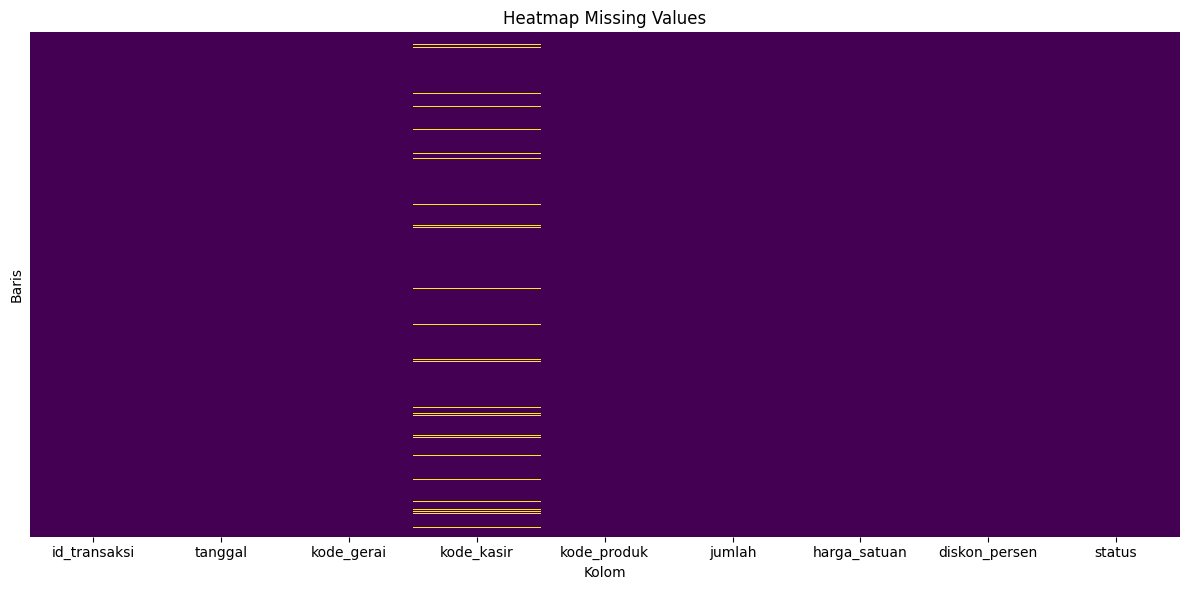

In [9]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isna(),
    cbar=False,
    cmap="viridis",
    yticklabels=False
)

plt.title("Heatmap Missing Values")
plt.xlabel("Kolom")
plt.ylabel("Baris")
plt.tight_layout()
plt.show()

In [10]:
print("Data duplikat:", df.duplicated().sum())

Data duplikat: 30


In [11]:
df.describe()

,jumlah,diskon_persen
count,5030.000000,5030.000000
mean,5.588469,2.563618
std,68.788887,5.211135
min,-12.000000,0.000000
25%,1.000000,0.000000
50%,2.000000,0.000000
75%,3.000000,0.000000
max,2375.000000,20.000000


# Data Cleaning

In [12]:
df_clean = df.copy()

In [13]:
print("missing value:", df_clean['kode_kasir'].isnull().sum())

missing value: 261


In [14]:
df_clean['kode_kasir'] = df_clean['kode_kasir'].fillna(
    'TIDAK DIKETAHUI'
)

In [15]:
print("Jumlah duplikat:", df_clean.duplicated().sum())

Jumlah duplikat: 30


In [16]:
df_clean = df_clean.drop_duplicates()

In [17]:
print(df_clean.shape)

(5000, 9)


In [18]:
print(df_clean['harga_satuan'].dtype)

df_clean['harga_satuan'].head(10)

object


,harga_satuan
0,13000
1,21000
2,"7500,00"
3,6500
4,6000
5,45500
6,18000
7,47500
8,"11000,00"
9,6500


In [19]:
df_clean['harga_satuan'] = pd.to_numeric(
    df_clean['harga_satuan'].astype(str).str.replace(
        ',', '.', regex=False
    ),
    errors='coerce'
)

In [20]:
print(df_clean['tanggal'].dtype)

df_clean['tanggal'].head(10)

object


,tanggal
0,2025-06-02
1,2024-12-28
2,2024-09-04
3,2025-07-30
4,26/03/2025
5,2025-07-18
6,2025-09-24
7,2024-10-09
8,2024-03-20
9,2024-03-22


In [21]:
df_clean['tanggal'] = pd.to_datetime(
    df_clean['tanggal'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
)

# Data Anomali

In [22]:
display(df_clean[df_clean['jumlah'] < 0])

,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
32,TRX0241782,2025-12-10,G04,K028,MIN1002,-6,45500.0,0,SELESAI
41,TRX0240181,2025-02-16,G07,K015,MKN1108,-12,9000.0,0,SELESAI
90,TRX0240898,2025-12-09,G05,K010,BYI1509,-3,46500.0,0,SELESAI
195,TRX0244719,2025-06-30,G03,K033,RMT1401,-1,10500.0,5,SELESAI
723,TRX0243147,2025-04-26,G09,TIDAK DIKETAHUI,MKN1106,-3,18500.0,0,SELESAI
847,TRX0241754,2025-02-06,G07,K017,BYI1502,-1,31000.0,10,BATAL
855,TRX0240649,2025-10-09,G12,K001,XXX9289,-2,13500.0,0,SELESAI
864,TRX0242385,2024-09-21,G08,K016,PRW1307,-2,9500.0,0,SELESAI
1054,TRX0243253,2025-04-30,G01,TIDAK DIKETAHUI,SGR1208,-1,33500.0,20,SELESAI
1495,TRX0241078,2024-07-28,G09,K002,MIN1005,-12,13500.0,10,RETUR


In [23]:
display(df_clean[df_clean['jumlah'] > 100])

,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
87,TRX0243886,2025-12-27,G03,K040,PRW1306,2375,14500.0,0,SELESAI
244,TRX0243257,2024-11-24,G01,K033,MKN1102,1456,32500.0,20,SELESAI
467,TRX0243696,2024-02-27,G06,TIDAK DIKETAHUI,SGR1201,892,54000.0,0,SELESAI
660,TRX0242847,2025-02-24,G11,K007,RMT1404,661,13000.0,5,BATAL
926,TRX0240632,2024-09-08,G07,K026,RMT1403,1280,6500.0,0,SELESAI
994,TRX0241002,2024-03-18,G11,K038,MKN1101,2093,48000.0,10,SELESAI
1035,TRX0241068,2025-09-17,G09,K032,SGR1202,759,13.5,5,SELESAI
1323,TRX0240401,2025-02-02,G08,K029,MIN1009,641,11500.0,0,SELESAI
2414,TRX0241473,2024-12-08,G06,K037,PRW1308,1310,11000.0,0,SELESAI
3220,TRX0242632,2025-11-19,G10,K009,SGR1204,746,41500.0,0,SELESAI


# Dataset Setelah Cleaning

In [24]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5000 entries, 0 to 5029
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   id_transaksi   5000 non-null   object        
 1   tanggal        5000 non-null   datetime64[ns]
 2   kode_gerai     5000 non-null   object        
 3   kode_kasir     5000 non-null   object        
 4   kode_produk    5000 non-null   object        
 5   jumlah         5000 non-null   int64         
 6   harga_satuan   5000 non-null   float64       
 7   diskon_persen  5000 non-null   int64         
 8   status         5000 non-null   object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(5)
memory usage: 390.6+ KB


In [25]:
print("Missing Value:")
print(df_clean.isnull().sum())

Missing Value:
id_transaksi     0
tanggal          0
kode_gerai       0
kode_kasir       0
kode_produk      0
jumlah           0
harga_satuan     0
diskon_persen    0
status           0
dtype: int64


In [26]:
print("Data duplikat:", df_clean.duplicated().sum())

Data duplikat: 0


In [27]:
print("Dataset sebelum cleaning:", df.shape)
print("Dataset setelah cleaning:", df_clean.shape)

Dataset sebelum cleaning: (5030, 9)
Dataset setelah cleaning: (5000, 9)


In [28]:
print("Tipe data tanggal:", df_clean['tanggal'].dtype)
print("Tipe data harga_satuan:", df_clean['harga_satuan'].dtype)

Tipe data tanggal: datetime64[ns]
Tipe data harga_satuan: float64


# Analisis Pendapatan

In [29]:
df_clean['pendapatan'] = (
    df_clean['jumlah'] *
    df_clean['harga_satuan'] *
    (1 - df_clean['diskon_persen'] / 100)
)

In [30]:
display(
    df_clean[
        ['jumlah', 'harga_satuan', 'diskon_persen', 'pendapatan']
    ].head(10)
)

,jumlah,harga_satuan,diskon_persen,pendapatan
0,4,13000.0,0,52000.0
1,1,21000.0,0,21000.0
2,3,7500.0,0,22500.0
3,2,6500.0,0,13000.0
4,1,6000.0,0,6000.0
5,12,45500.0,10,491400.0
6,1,18000.0,0,18000.0
7,4,47500.0,10,171000.0
8,3,11000.0,0,33000.0
9,2,6500.0,0,13000.0


In [31]:
df_clean['tahun'] = df_clean['tanggal'].dt.year

data_2024 = df_clean[df_clean['tahun'] == 2024].copy()
data_2025 = df_clean[df_clean['tahun'] == 2025].copy()

print("Jumlah data tahun 2024:", len(data_2024))
print("Jumlah data tahun 2025:", len(data_2025))

Jumlah data tahun 2024: 2492
Jumlah data tahun 2025: 2508


In [32]:
pendapatan_2024 = data_2024['pendapatan'].sum()
pendapatan_2025 = data_2025['pendapatan'].sum()

print(f"Total pendapatan tahun 2024: Rp {pendapatan_2024:,.0f}")
print(f"Total pendapatan tahun 2025: Rp {pendapatan_2025:,.0f}")

Total pendapatan tahun 2024: Rp 392,499,527
Total pendapatan tahun 2025: Rp 261,083,324


In [33]:
hasil = pd.DataFrame({
    'Tahun': [2024, 2025],
    'Jumlah Data': [len(data_2024), len(data_2025)],
    'Total Pendapatan': [
        pendapatan_2024,
        pendapatan_2025
    ]
})

display(hasil.style.format({
    'Total Pendapatan': 'Rp {:,.0f}'.format
}))

,Tahun,Jumlah Data,Total Pendapatan
0,2024,2492,"Rp 392,499,527"
1,2025,2508,"Rp 261,083,324"


# Kesimpulan Pendapatan

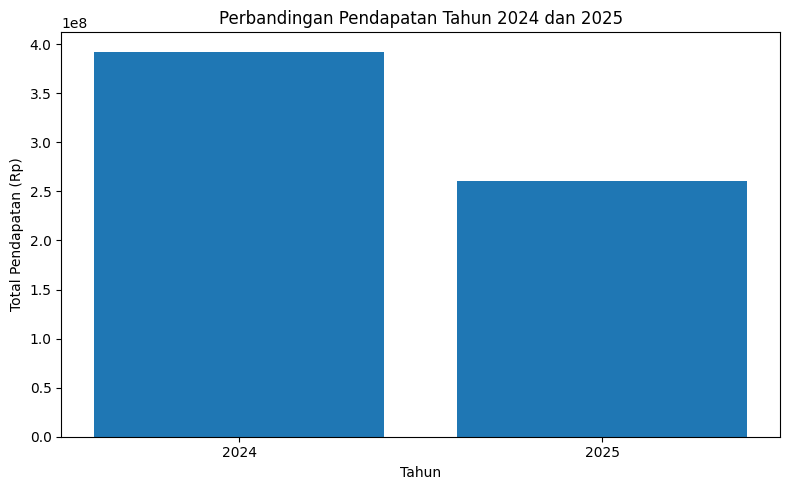

In [34]:
plt.figure(figsize=(8, 5))

plt.bar(
    hasil['Tahun'].astype(str),
    hasil['Total Pendapatan']
)

plt.title('Perbandingan Pendapatan Tahun 2024 dan 2025')
plt.xlabel('Tahun')
plt.ylabel('Total Pendapatan (Rp)')

plt.tight_layout()
plt.show()

In [35]:
print("KESIMPULAN PENDAPATAN")
print("=========================")

print("Jumlah data tahun 2024:", len(data_2024))
print("Jumlah data tahun 2025:", len(data_2025))

print(f"\nPendapatan tahun 2024: Rp {pendapatan_2024:,.0f}")
print(f"Pendapatan tahun 2025: Rp {pendapatan_2025:,.0f}")

print(
    f"\nTotal pendapatan kedua tahun: "
    f"Rp {pendapatan_2024 + pendapatan_2025:,.0f}"
)

KESIMPULAN PENDAPATAN
Jumlah data tahun 2024: 2492
Jumlah data tahun 2025: 2508

Pendapatan tahun 2024: Rp 392,499,527
Pendapatan tahun 2025: Rp 261,083,324

Total pendapatan kedua tahun: Rp 653,582,851


# Pisah Data Anomali

In [36]:
print("Data nilai minus (<1):",
      (df_clean['jumlah'] < 0).sum())

Data nilai minus (<1): 40


In [37]:
print("Data nilai besar (>100):",
      (df_clean['jumlah'] > 100).sum())

Data nilai besar (>100): 12


In [38]:
data_minus = df_clean[df_clean['jumlah'] < 0].copy()

In [39]:
display(data_minus)

,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status,pendapatan,tahun
32,TRX0241782,2025-12-10,G04,K028,MIN1002,-6,45500.0,0,SELESAI,-273000.0,2025
41,TRX0240181,2025-02-16,G07,K015,MKN1108,-12,9000.0,0,SELESAI,-108000.0,2025
90,TRX0240898,2025-12-09,G05,K010,BYI1509,-3,46500.0,0,SELESAI,-139500.0,2025
195,TRX0244719,2025-06-30,G03,K033,RMT1401,-1,10500.0,5,SELESAI,-9975.0,2025
723,TRX0243147,2025-04-26,G09,TIDAK DIKETAHUI,MKN1106,-3,18500.0,0,SELESAI,-55500.0,2025
847,TRX0241754,2025-02-06,G07,K017,BYI1502,-1,31000.0,10,BATAL,-27900.0,2025
855,TRX0240649,2025-10-09,G12,K001,XXX9289,-2,13500.0,0,SELESAI,-27000.0,2025
864,TRX0242385,2024-09-21,G08,K016,PRW1307,-2,9500.0,0,SELESAI,-19000.0,2024
1054,TRX0243253,2025-04-30,G01,TIDAK DIKETAHUI,SGR1208,-1,33500.0,20,SELESAI,-26800.0,2025
1495,TRX0241078,2024-07-28,G09,K002,MIN1005,-12,13500.0,10,RETUR,-145800.0,2024


In [40]:
data_besar = df_clean[df_clean['jumlah'] > 100].copy()

In [41]:
display(data_besar)

,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status,pendapatan,tahun
87,TRX0243886,2025-12-27,G03,K040,PRW1306,2375,14500.0,0,SELESAI,3.443750e+07,2025
244,TRX0243257,2024-11-24,G01,K033,MKN1102,1456,32500.0,20,SELESAI,3.785600e+07,2024
467,TRX0243696,2024-02-27,G06,TIDAK DIKETAHUI,SGR1201,892,54000.0,0,SELESAI,4.816800e+07,2024
660,TRX0242847,2025-02-24,G11,K007,RMT1404,661,13000.0,5,BATAL,8.163350e+06,2025
926,TRX0240632,2024-09-08,G07,K026,RMT1403,1280,6500.0,0,SELESAI,8.320000e+06,2024
994,TRX0241002,2024-03-18,G11,K038,MKN1101,2093,48000.0,10,SELESAI,9.041760e+07,2024
1035,TRX0241068,2025-09-17,G09,K032,SGR1202,759,13.5,5,SELESAI,9.734175e+03,2025
1323,TRX0240401,2025-02-02,G08,K029,MIN1009,641,11500.0,0,SELESAI,7.371500e+06,2025
2414,TRX0241473,2024-12-08,G06,K037,PRW1308,1310,11000.0,0,SELESAI,1.441000e+07,2024
3220,TRX0242632,2025-11-19,G10,K009,SGR1204,746,41500.0,0,SELESAI,3.095900e+07,2025


In [42]:
data_normal = df_clean[
    (df_clean['jumlah'] >= 0) &
    (df_clean['jumlah'] <= 100)
].copy()

In [43]:
display(data_normal.head(10))

,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status,pendapatan,tahun
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000.0,0,SELESAI,52000.0,2025
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000.0,0,SELESAI,21000.0,2024
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,7500.0,0,SELESAI,22500.0,2024
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500.0,0,SELESAI,13000.0,2025
4,TRX0243509,2025-03-26,G05,K016,RMT1407,1,6000.0,0,SELESAI,6000.0,2025
5,TRX0240658,2025-07-18,G01,K008,RMT1408,12,45500.0,10,SELESAI,491400.0,2025
6,TRX0244581,2025-09-24,G10,K021,MIN1004,1,18000.0,0,SELESAI,18000.0,2025
7,TRX0241251,2024-10-09,G09,K035,SGR1204,4,47500.0,10,SELESAI,171000.0,2024
8,TRX0244274,2024-03-20,G07,K011,BYI1508,3,11000.0,0,SELESAI,33000.0,2024
9,TRX0243163,2024-03-22,G08,K028,PRW1304,2,6500.0,0,BATAL,13000.0,2024


In [44]:
print("Jumlah data minus:", len(data_minus))
print("Jumlah data besar:", len(data_besar))
print("Jumlah data normal:", len(data_normal))

Jumlah data minus: 40
Jumlah data besar: 12
Jumlah data normal: 4948


# Data Tanpa Anomali

In [45]:
display(data_normal.head(10))

,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status,pendapatan,tahun
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000.0,0,SELESAI,52000.0,2025
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000.0,0,SELESAI,21000.0,2024
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,7500.0,0,SELESAI,22500.0,2024
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500.0,0,SELESAI,13000.0,2025
4,TRX0243509,2025-03-26,G05,K016,RMT1407,1,6000.0,0,SELESAI,6000.0,2025
5,TRX0240658,2025-07-18,G01,K008,RMT1408,12,45500.0,10,SELESAI,491400.0,2025
6,TRX0244581,2025-09-24,G10,K021,MIN1004,1,18000.0,0,SELESAI,18000.0,2025
7,TRX0241251,2024-10-09,G09,K035,SGR1204,4,47500.0,10,SELESAI,171000.0,2024
8,TRX0244274,2024-03-20,G07,K011,BYI1508,3,11000.0,0,SELESAI,33000.0,2024
9,TRX0243163,2024-03-22,G08,K028,PRW1304,2,6500.0,0,BATAL,13000.0,2024


In [46]:
print("Jumlah data normal:", len(data_normal))

Jumlah data normal: 4948


In [47]:
normal_2024 = data_normal[
    data_normal['tahun'] == 2024
].copy()

normal_2025 = data_normal[
    data_normal['tahun'] == 2025
].copy()

print("Data normal tahun 2024:", len(normal_2024))
print("Data normal tahun 2025:", len(normal_2025))

Data normal tahun 2024: 2468
Data normal tahun 2025: 2480


In [48]:
pendapatan_normal_2024 = normal_2024['pendapatan'].sum()
pendapatan_normal_2025 = normal_2025['pendapatan'].sum()

print(f"Pendapatan normal 2024: Rp {pendapatan_normal_2024:,.0f}")
print(f"Pendapatan normal 2025: Rp {pendapatan_normal_2025:,.0f}")

Pendapatan normal 2024: Rp 133,840,427
Pendapatan normal 2025: Rp 140,638,815


In [49]:
hasil_normal = pd.DataFrame({
    'Tahun': [2024, 2025],
    'Jumlah Data': [len(normal_2024), len(normal_2025)],
    'Total Pendapatan': [
        pendapatan_normal_2024,
        pendapatan_normal_2025
    ]
})

display(hasil_normal.style.format({
    'Total Pendapatan': 'Rp {:,.0f}'.format
}))

,Tahun,Jumlah Data,Total Pendapatan
0,2024,2468,"Rp 133,840,427"
1,2025,2480,"Rp 140,638,815"


# Kesimpulan Tanpa Anomali

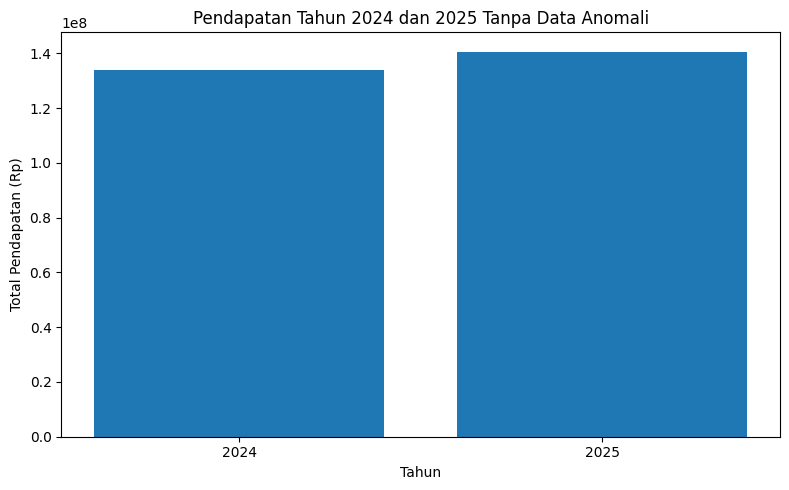

In [50]:
plt.figure(figsize=(8, 5))

plt.bar(
    hasil_normal['Tahun'].astype(str),
    hasil_normal['Total Pendapatan']
)

plt.title('Pendapatan Tahun 2024 dan 2025 Tanpa Data Anomali')
plt.xlabel('Tahun')
plt.ylabel('Total Pendapatan (Rp)')

plt.tight_layout()
plt.show()

In [51]:
print("Jumlah data normal tahun 2024:", len(normal_2024))
print("Jumlah data normal tahun 2025:", len(normal_2025))

print(f"\nPendapatan normal tahun 2024: Rp {pendapatan_normal_2024:,.0f}")
print(f"Pendapatan normal tahun 2025: Rp {pendapatan_normal_2025:,.0f}")

print(
    f"\nTotal pendapatan normal kedua tahun: "
    f"Rp {pendapatan_normal_2024 + pendapatan_normal_2025:,.0f}"
)

Jumlah data normal tahun 2024: 2468
Jumlah data normal tahun 2025: 2480

Pendapatan normal tahun 2024: Rp 133,840,427
Pendapatan normal tahun 2025: Rp 140,638,815

Total pendapatan normal kedua tahun: Rp 274,479,242


# Perbandingan Data Dengan Anomali dan Tanpa Anomali

In [52]:
perbandingan = pd.DataFrame({
    'Tahun': [2024, 2025],

    'Pendapatan Dengan Anomali': [
        pendapatan_2024,
        pendapatan_2025
    ],

    'Pendapatan Tanpa Anomali': [
        pendapatan_normal_2024,
        pendapatan_normal_2025
    ]
})

display(perbandingan.style.format({
    'Pendapatan Dengan Anomali': 'Rp {:,.0f}'.format,
    'Pendapatan Tanpa Anomali': 'Rp {:,.0f}'.format
}))

,Tahun,Pendapatan Dengan Anomali,Pendapatan Tanpa Anomali
0,2024,"Rp 392,499,527","Rp 133,840,427"
1,2025,"Rp 261,083,324","Rp 140,638,815"


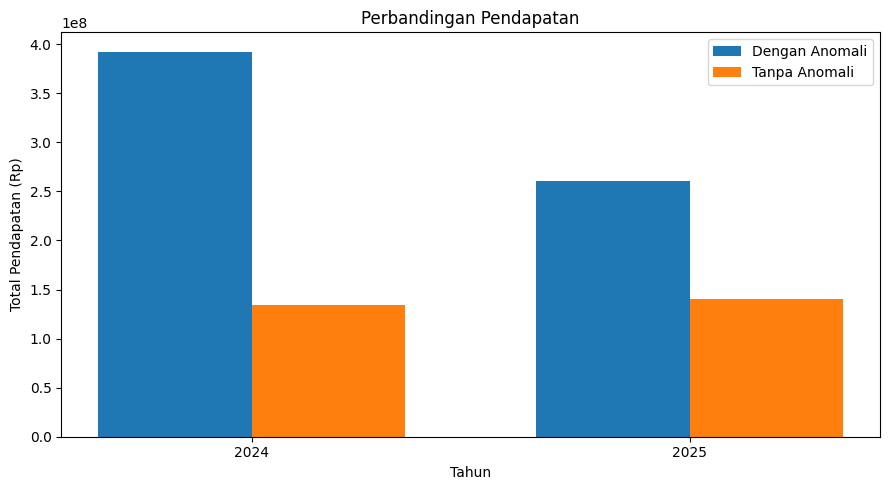

In [53]:
tahun = ['2024', '2025']

dengan_anomali = [
    pendapatan_2024,
    pendapatan_2025
]

tanpa_anomali = [
    pendapatan_normal_2024,
    pendapatan_normal_2025
]

x = np.arange(len(tahun))
lebar = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - lebar/2,
    dengan_anomali,
    lebar,
    label='Dengan Anomali'
)

plt.bar(
    x + lebar/2,
    tanpa_anomali,
    lebar,
    label='Tanpa Anomali'
)

plt.title('Perbandingan Pendapatan')
plt.xlabel('Tahun')
plt.ylabel('Total Pendapatan (Rp)')

plt.xticks(x, tahun)
plt.legend()
plt.tight_layout()
plt.show()

In [54]:
print("KESIMPULAN PERBANDINGAN")
print("========================")

print("\nTAHUN 2024")
print(f"Pendapatan dengan anomali    : Rp {pendapatan_2024:,.0f}")
print(f"Pendapatan tanpa anomali     : Rp {pendapatan_normal_2024:,.0f}")

print("\nTAHUN 2025")
print(f"Pendapatan dengan anomali    : Rp {pendapatan_2025:,.0f}")
print(f"Pendapatan tanpa anomali     : Rp {pendapatan_normal_2025:,.0f}")

KESIMPULAN PERBANDINGAN

TAHUN 2024
Pendapatan dengan anomali    : Rp 392,499,527
Pendapatan tanpa anomali     : Rp 133,840,427

TAHUN 2025
Pendapatan dengan anomali    : Rp 261,083,324
Pendapatan tanpa anomali     : Rp 140,638,815
